# 03. Прогнозирование числа рейсов и доли задержек

**Ограничение сценария:** ретроспективный прогноз на сутки вперёд при доступной истории до предыдущего дня. BTS публикуется с задержкой, поэтому это не проверка оперативного прогноза в реальном времени. Фактическая погода прогнозируемого дня исключена.


## 1. Импорты и поиск проекта
Корень определяется автоматически из текущего каталога или его родителей. Пароль берётся существующим `src.database.get_engine` из `.env`; в вывод он не попадает.


In [2]:
from pathlib import Path
import sys, json, hashlib, platform, importlib.metadata
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sqlalchemy import text
from sklearn.metrics import mean_absolute_error, mean_squared_error
from catboost import CatBoostRegressor

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'src/database.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Переместите тетрадь в notebooks проекта aviation-analytics и откройте проект в VS Code.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.database import get_engine

SEED = 42
TARGETS = ['total_flights', 'delay_share']
AIRPORTS = ['ATL', 'DFW', 'JFK', 'LAX', 'ORD']
TRAIN_END = pd.Timestamp('2024-12-31')
VALID_END = pd.Timestamp('2025-06-30')
TEST_END = pd.Timestamp('2025-12-31')
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT = ROOT / 'reports' / 'forecasting' / RUN_ID
MODEL_DIR = ROOT / 'models' / 'forecasting' / RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
MODEL_DIR.mkdir(parents=True, exist_ok=False)
pd.set_option('display.max_columns', 30)
plt.rcParams['figure.figsize'] = (13, 4)
print('Проект:', ROOT)
print('Результаты:', OUT)
print('Python:', platform.python_version())


Проект: d:\MIREA\ПАС\aviation-analytics
Результаты: d:\MIREA\ПАС\aviation-analytics\reports\forecasting\20261026T151541584865Z
Python: 3.14.3


## 2. Чтение Gold и контроль целевых показателей
Выгружаем зафиксированный период 2023–2025 из существующего представления. Отдельно сверяем знаменатель и числитель доли задержек с Gold. Никаких синтетических данных в рабочем запуске не используется.


In [3]:
engine = get_engine()
query = text("""
SELECT airport_id, airport_code, flight_date,
       total_flights, completed_flights, cancelled_flights,
       diverted_flights, delayed_flights, delay_share,
       avg_temperature, total_precipitation, avg_wind_speed, max_wind_gust
FROM gold.airport_daily_bi
WHERE flight_date BETWEEN :date_from AND :date_to
ORDER BY airport_code, flight_date
""")
with engine.connect() as connection:
    raw = pd.read_sql(query, connection, params={'date_from': '2023-01-01', 'date_to': '2025-12-31'})
raw['flight_date'] = pd.to_datetime(raw['flight_date'])
raw['airport_code'] = raw['airport_code'].astype(str)
num_cols = [c for c in raw if c not in ['airport_code', 'flight_date']]
raw[num_cols] = raw[num_cols].apply(pd.to_numeric, errors='raise')
raw = raw.sort_values(['airport_code', 'flight_date']).reset_index(drop=True)
assert not raw.empty, 'Gold пуст: проверьте подключение и загрузку истории.'
assert set(raw.airport_code) == set(AIRPORTS), 'Ожидаются ровно пять аэропортов.'
assert not raw.duplicated(['airport_code', 'flight_date']).any(), 'Повторяющиеся даты.'
assert not raw[TARGETS].isna().any().any(), 'Есть пропуски в целях.'
counts = ['total_flights', 'completed_flights', 'cancelled_flights', 'diverted_flights', 'delayed_flights']
assert np.isfinite(raw[counts + ['delay_share']].to_numpy(dtype=float)).all()
assert (raw[counts] >= 0).all().all()
assert (raw[counts] % 1 == 0).all().all()
assert (raw.completed_flights > 0).all(), 'При нулевом знаменателе доля не определена.'
assert (raw.completed_flights <= raw.total_flights).all()
assert (raw.delayed_flights <= raw.completed_flights).all(), 'Проверьте определение is_delayed_15 в Silver.'
assert raw.delay_share.between(0, 100).all()
expected_share = 100 * raw.delayed_flights / raw.completed_flights
assert np.allclose(raw.delay_share, expected_share, atol=1e-6), 'Формула delay_share не совпадает.'
expected_dates = pd.date_range('2023-01-01', '2025-12-31')
for airport, group in raw.groupby('airport_code'):
    assert pd.DatetimeIndex(group.flight_date).equals(expected_dates), f'Неполный ряд {airport}'
summary = raw.groupby('airport_code').agg(date_from=('flight_date','min'), date_to=('flight_date','max'), days=('flight_date','size'), flights=('total_flights','sum'), cancelled=('cancelled_flights','sum'))
display(summary)
display(raw.head())
print('Все проверки пройдены. Строк:', len(raw))
raw.to_csv(OUT / 'gold_snapshot.csv', index=False, encoding='utf-8-sig')
snapshot_sha256 = hashlib.sha256((OUT / 'gold_snapshot.csv').read_bytes()).hexdigest()
print('SHA256 снимка:', snapshot_sha256)


,date_from,date_to,days,flights,cancelled
airport_code,,,,,
ATL,2023-01-01,2025-12-31,1096,992806,10714
DFW,2023-01-01,2025-12-31,1096,914680,18957
JFK,2023-01-01,2025-12-31,1096,361156,7464
LAX,2023-01-01,2025-12-31,1096,578878,4469
ORD,2023-01-01,2025-12-31,1096,865947,12593


,airport_id,airport_code,flight_date,total_flights,completed_flights,cancelled_flights,diverted_flights,delayed_flights,delay_share,avg_temperature,total_precipitation,avg_wind_speed,max_wind_gust
0,10,ATL,2023-01-01,706,696,10,10,161,23.132184,13.775000,0.5,9.116667,27.4
1,10,ATL,2023-01-02,873,858,15,5,372,43.356643,14.287500,2.4,9.675000,31.0
2,10,ATL,2023-01-03,848,827,21,5,412,49.818622,17.200000,8.2,16.316667,43.2
3,10,ATL,2023-01-04,828,785,43,2,485,61.783439,16.829167,12.5,15.358333,40.7
4,10,ATL,2023-01-05,823,821,2,2,187,22.777101,10.437500,0.0,12.833333,38.5


Все проверки пройдены. Строк: 5480
SHA256 снимка: 1a508e3d341058f3fbfb356e67447be647c7dfefc8793a2ef01636d9e10a2cf3


## 3. Признаки: только информация из прошлого
Для дня t доступны календарь t, показатели и погода до t−1. Все сдвиги выполняются внутри аэропорта; средние сначала сдвигаются, затем рассчитываются. Пропущенную погоду заменяет CatBoost, но бесконечности недопустимы. Первые 28 дней каждого ряда исключаются из обучения из-за неполной истории.

`cancelled_flights` и погода используются только за прошлые дни. Отмена и погода дня t не передаются модели.


In [4]:
WEATHER = ['avg_temperature', 'total_precipitation', 'avg_wind_speed', 'max_wind_gust']
def make_features(frame):
    df = frame.sort_values(['airport_code', 'flight_date']).copy()
    date = df['flight_date']
    df['day_of_week'] = date.dt.dayofweek
    df['month'] = date.dt.month
    df['is_weekend'] = (date.dt.dayofweek >= 5).astype(int)
    df['time_index'] = (date - pd.Timestamp('2023-01-01')).dt.days
    df['year_sin'] = np.sin(2 * np.pi * (date.dt.dayofyear - 1) / 365.25)
    df['year_cos'] = np.cos(2 * np.pi * (date.dt.dayofyear - 1) / 365.25)
    for col in TARGETS + ['cancelled_flights']:
        group = df.groupby('airport_code')[col]
        for lag in [1, 7, 14, 28]:
            df[f'{col}_lag_{lag}'] = group.shift(lag)
        for window in [7, 28]:
            df[f'{col}_mean_{window}'] = group.transform(lambda x: x.shift(1).rolling(window, min_periods=window).mean())
    for col in WEATHER:
        df[f'{col}_lag_1'] = df.groupby('airport_code')[col].shift(1)
        df[f'{col}_mean_7'] = df.groupby('airport_code')[col].transform(lambda x: x.shift(1).rolling(7, min_periods=1).mean())
    return df

featured = make_features(raw)
calendar = ['day_of_week','month','is_weekend','time_index','year_sin','year_cos']
FEATURES = ['airport_code'] + calendar + [c for c in featured if '_lag_' in c or '_mean_' in c]
required_history = [c for c in FEATURES if c.startswith(tuple(TARGETS + ['cancelled_flights']))]
data = featured.dropna(subset=required_history).copy()
assert not np.isinf(data[[c for c in FEATURES if c != 'airport_code']].to_numpy(dtype=float)).any()
assert set(TARGETS).isdisjoint(FEATURES)
# Контроль зависимости: изменение фактов дня t и будущего не меняет признаки t.
cut = pd.Timestamp('2025-03-01')
changed = raw.copy()
changed.loc[changed.flight_date >= cut, TARGETS + ['cancelled_flights'] + WEATHER] = 999.0
changed_features = make_features(changed)
pd.testing.assert_frame_equal(featured.loc[featured.flight_date == cut, FEATURES], changed_features.loc[changed_features.flight_date == cut, FEATURES])
display(data.groupby('airport_code').agg(first_date=('flight_date','min'), last_date=('flight_date','max'), rows=('flight_date','size')))
display(data[FEATURES].isna().sum().rename('missing').to_frame().query('missing > 0'))
print('Признаков:', len(FEATURES), '| Контроль отсутствия зависимости от будущего пройден.')


,first_date,last_date,rows
airport_code,,,
ATL,2023-01-29,2025-12-31,1068
DFW,2023-01-29,2025-12-31,1068
JFK,2023-01-29,2025-12-31,1068
LAX,2023-01-29,2025-12-31,1068
ORD,2023-01-29,2025-12-31,1068


,missing


Признаков: 33 | Контроль отсутствия зависимости от будущего пройден.


## 4. Обучение, валидация и тест по времени
Обучение: 2023–2024; валидация: январь–июнь 2025; тест: июль–декабрь 2025. На тесте выполняется последовательный однодневный прогноз: для 10 июля фактические данные 9 июля уже доступны. Это не многодневный прогноз всего полугодия из одной точки.


,part,date_from,date_to,rows,airports
0,train,2023-01-29,2024-12-31,3515,5
1,validation,2025-01-01,2025-06-30,905,5
2,test,2025-07-01,2025-12-31,920,5


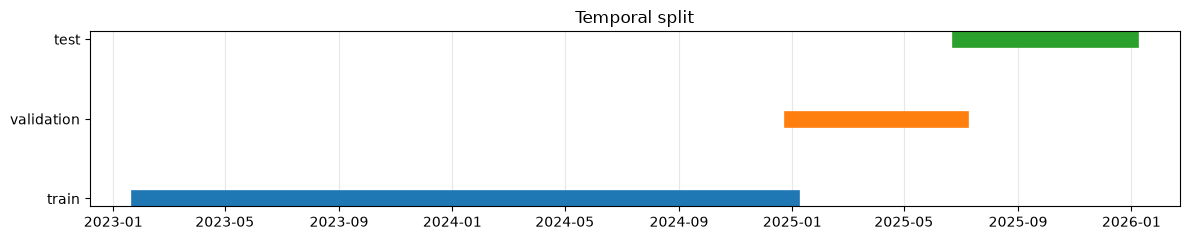

In [5]:
train = data.loc[data.flight_date <= TRAIN_END].copy()
valid = data.loc[(data.flight_date > TRAIN_END) & (data.flight_date <= VALID_END)].copy()
test = data.loc[(data.flight_date > VALID_END) & (data.flight_date <= TEST_END)].copy()
train_valid = data.loc[data.flight_date <= VALID_END].copy()
assert train.flight_date.max() < valid.flight_date.min()
assert valid.flight_date.max() < test.flight_date.min()
parts = []
for name, frame in [('train',train), ('validation',valid), ('test',test)]:
    assert len(frame) > 0
    parts.append({'part':name,'date_from':frame.flight_date.min(),'date_to':frame.flight_date.max(),'rows':len(frame),'airports':frame.airport_code.nunique()})
split_summary = pd.DataFrame(parts)
display(split_summary)
split_summary.to_csv(OUT / 'splits.csv', index=False)
fig, ax = plt.subplots(figsize=(12, 2.5))
for i, row in split_summary.iterrows():
    ax.plot([row.date_from, row.date_to], [i,i], linewidth=12, label=row['part'])
ax.set_yticks(range(3), split_summary['part']); ax.set_title('Temporal split'); ax.grid(axis='x', alpha=.3)
fig.tight_layout(); fig.savefig(OUT / 'temporal_split.png', dpi=160); plt.show()


## 5. Функции оценки и сезонный baseline
Baseline повторяет фактическое значение того же дня недели неделю назад. MAE числа рейсов измеряется в рейсах; MAE доли — в процентных пунктах. RMSE сильнее штрафует крупные ошибки. Метрики считаются по каждому аэропорту и по всем строкам вместе; общая ошибка числа рейсов зависит от масштаба аэропортов.


In [6]:
def bounded(values, target):
    values = np.asarray(values, dtype=float)
    return np.clip(values, 0, 100 if target == 'delay_share' else np.inf)

def prediction_rows(frame, target, model, values, split):
    out = frame[['airport_code','flight_date']].copy()
    out['target'] = target; out['model'] = model; out['split'] = split
    out['actual'] = frame[target].to_numpy(dtype=float)
    out['prediction'] = bounded(values, target)
    out['history_through'] = out.flight_date - pd.Timedelta(days=1)
    return out

def score_predictions(predictions):
    records = []
    for (split, target, model), group in predictions.groupby(['split','target','model']):
        subsets = [('ALL',group)] + list(group.groupby('airport_code'))
        for airport, part in subsets:
            records.append({'split':split,'target':target,'model':model,'airport_code':airport,'n':len(part),
                            'MAE':mean_absolute_error(part.actual,part.prediction),
                            'RMSE':np.sqrt(mean_squared_error(part.actual,part.prediction))})
    return pd.DataFrame(records)

validation_predictions = [prediction_rows(valid, target, 'seasonal_naive_7', valid[f'{target}_lag_7'], 'validation') for target in TARGETS]
display(score_predictions(pd.concat(validation_predictions)).round(3))


,split,target,model,airport_code,n,MAE,RMSE
0,validation,delay_share,seasonal_naive_7,ALL,905,11.783,17.100
1,validation,delay_share,seasonal_naive_7,ATL,181,14.925,21.349
2,validation,delay_share,seasonal_naive_7,DFW,181,16.481,22.425
3,validation,delay_share,seasonal_naive_7,JFK,181,9.888,12.951
4,validation,delay_share,seasonal_naive_7,LAX,181,5.871,7.617
5,validation,delay_share,seasonal_naive_7,ORD,181,11.752,16.662
6,validation,total_flights,seasonal_naive_7,ALL,905,15.027,29.754
7,validation,total_flights,seasonal_naive_7,ATL,181,24.961,45.192
8,validation,total_flights,seasonal_naive_7,DFW,181,14.878,29.719
9,validation,total_flights,seasonal_naive_7,JFK,181,5.917,9.962


## 6. Выбор CatBoost только на валидации
Два заранее заданных варианта глубины; early stopping смотрит только на валидацию. Для каждой цели выбираем вариант с наименьшим validation MAE. Тест ещё не используется. Общая модель для пяти аэропортов учитывает код аэропорта как категорию.


In [7]:
BASE_PARAMS = dict(loss_function='RMSE', eval_metric='MAE', iterations=1200,
                   learning_rate=0.04, random_seed=SEED, thread_count=4,
                   allow_writing_files=False)
selected = {}; tuning = []; validation_models = {}
for target in TARGETS:
    candidates = []
    for depth in [4, 6]:
        model = CatBoostRegressor(**BASE_PARAMS, depth=depth)
        model.fit(train[FEATURES], train[target], cat_features=['airport_code'],
                  eval_set=(valid[FEATURES],valid[target]), early_stopping_rounds=80, verbose=False)
        pred = bounded(model.predict(valid[FEATURES]), target)
        mae = mean_absolute_error(valid[target],pred)
        tuning.append({'target':target,'depth':depth,'trees':model.tree_count_,'validation_MAE':mae})
        candidates.append((mae,depth,model))
        print(target, '| depth:', depth, '| trees:', model.tree_count_, '| validation MAE:', round(mae,4))
    _, depth, best = min(candidates, key=lambda item:item[0])
    selected[target] = {'depth':depth,'iterations':int(best.tree_count_)}
    validation_models[target] = best
    validation_predictions.append(prediction_rows(valid,target,'catboost',best.predict(valid[FEATURES]),'validation'))
tuning_table = pd.DataFrame(tuning)
validation_predictions = pd.concat(validation_predictions,ignore_index=True)
validation_metrics = score_predictions(validation_predictions)
display(tuning_table.round(4))
display(validation_metrics.query("airport_code == 'ALL'").round(4))
# Рабочую модель выбираем по валидации, а не по тесту.
chosen_model = {}
for target in TARGETS:
    m = validation_metrics.query("airport_code == 'ALL' and target == @target")
    chosen_model[target] = m.sort_values(['MAE','model']).iloc[0]['model']
print('Выбор по валидации:', chosen_model)


total_flights | depth: 4 | trees: 225 | validation MAE: 25.5474
total_flights | depth: 6 | trees: 273 | validation MAE: 26.3921
delay_share | depth: 4 | trees: 78 | validation MAE: 7.186
delay_share | depth: 6 | trees: 66 | validation MAE: 7.1572


,target,depth,trees,validation_MAE
0,total_flights,4,225,25.5474
1,total_flights,6,273,26.3921
2,delay_share,4,78,7.1860
3,delay_share,6,66,7.1572


,split,target,model,airport_code,n,MAE,RMSE
0,validation,delay_share,catboost,ALL,905,7.1572,10.3494
6,validation,delay_share,seasonal_naive_7,ALL,905,11.7833,17.1002
12,validation,total_flights,catboost,ALL,905,25.5474,33.9487
18,validation,total_flights,seasonal_naive_7,ALL,905,15.0265,29.7544


Выбор по валидации: {'total_flights': 'seasonal_naive_7', 'delay_share': 'catboost'}


## 7. Финальное обучение и однократная тестовая оценка
Фиксируем параметры, переобучаем CatBoost на данных до 30 июня 2025 включительно. Тест не передаётся в `eval_set`. Сравниваем обе модели, но не меняем параметры по тестовым результатам. Повторный запуск с теми же настройками воспроизводит эксперимент; подбор по тесту нарушит независимость оценки.


In [8]:
final_models = {}; test_parts = []
for target in TARGETS:
    params = {**BASE_PARAMS, **selected[target]}
    model = CatBoostRegressor(**params)
    model.fit(train_valid[FEATURES],train_valid[target],cat_features=['airport_code'],verbose=False)
    final_models[target] = model
    model.save_model(str(MODEL_DIR / f'{target}_evaluation.cbm'))
    test_parts.append(prediction_rows(test,target,'seasonal_naive_7',test[f'{target}_lag_7'],'test'))
    test_parts.append(prediction_rows(test,target,'catboost',model.predict(test[FEATURES]),'test'))
test_predictions = pd.concat(test_parts,ignore_index=True)
test_metrics = score_predictions(test_predictions)
display(test_metrics.round(4))
comparison = test_metrics.pivot(index=['target','airport_code'],columns='model',values='MAE').reset_index()
comparison['improvement_pct'] = np.where(comparison.seasonal_naive_7 != 0,
    100 * (comparison.seasonal_naive_7-comparison.catboost)/comparison.seasonal_naive_7,np.nan)
display(comparison.round(3))
print('Положительное improvement_pct: CatBoost лучше baseline; отрицательное: хуже.')


,split,target,model,airport_code,n,MAE,RMSE
0,test,delay_share,catboost,ALL,920,6.3320,9.6339
1,test,delay_share,catboost,ATL,184,6.4735,9.1671
2,test,delay_share,catboost,DFW,184,6.6067,10.2416
3,test,delay_share,catboost,JFK,184,6.7425,9.4284
4,test,delay_share,catboost,LAX,184,3.8562,5.1552
5,test,delay_share,catboost,ORD,184,7.9811,12.6357
6,test,delay_share,seasonal_naive_7,ALL,920,10.1624,14.7364
7,test,delay_share,seasonal_naive_7,ATL,184,10.3475,14.6833
8,test,delay_share,seasonal_naive_7,DFW,184,11.6997,16.6163
9,test,delay_share,seasonal_naive_7,JFK,184,10.7907,14.2086


model,target,airport_code,catboost,seasonal_naive_7,improvement_pct
0,delay_share,ALL,6.332,10.162,37.692
1,delay_share,ATL,6.474,10.348,37.439
2,delay_share,DFW,6.607,11.700,43.531
3,delay_share,JFK,6.743,10.791,37.515
4,delay_share,LAX,3.856,5.304,27.304
5,delay_share,ORD,7.981,12.670,37.006
6,total_flights,ALL,27.088,27.242,0.566
7,total_flights,ATL,37.084,39.685,6.553
8,total_flights,DFW,33.625,33.984,1.056
9,total_flights,JFK,10.549,6.859,-53.804


Положительное improvement_pct: CatBoost лучше baseline; отрицательное: хуже.


## 8. Графики факта, прогнозов и важности признаков
Для подробного просмотра измените аэропорт и диапазон, не подбирая по ним параметры модели. Важность признаков характеризует использование данных моделью и не доказывает причинного влияния.


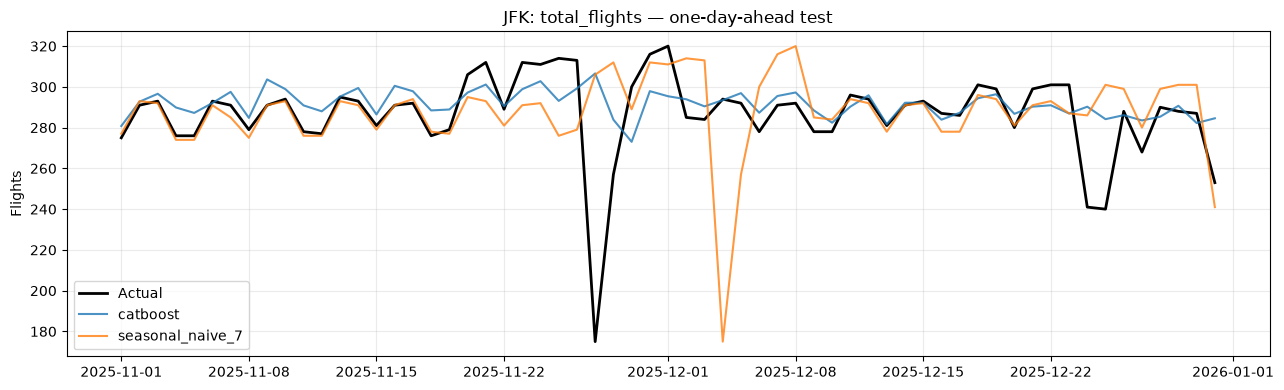

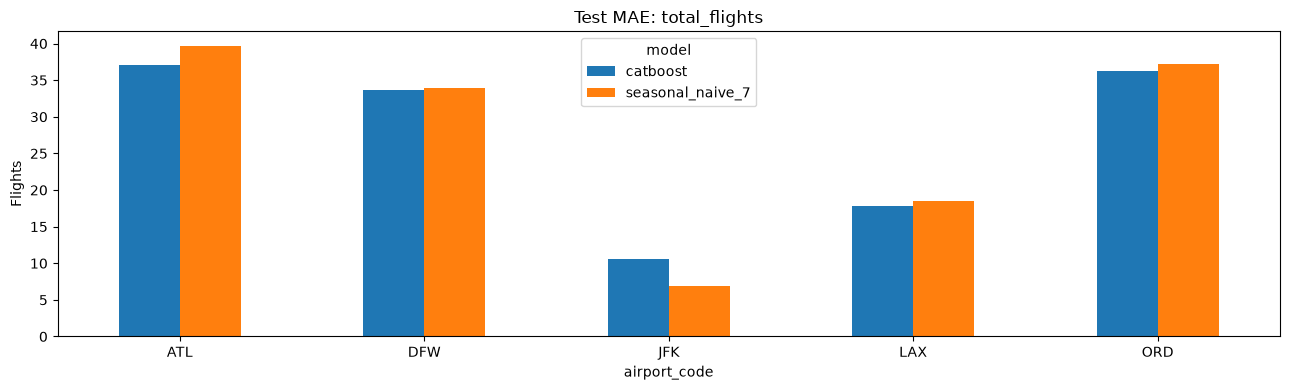

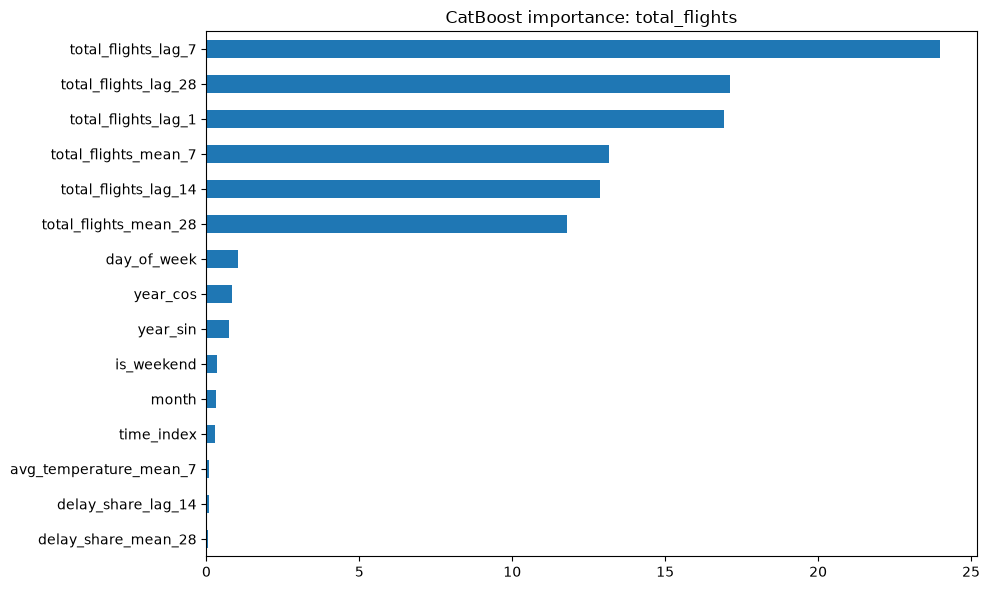

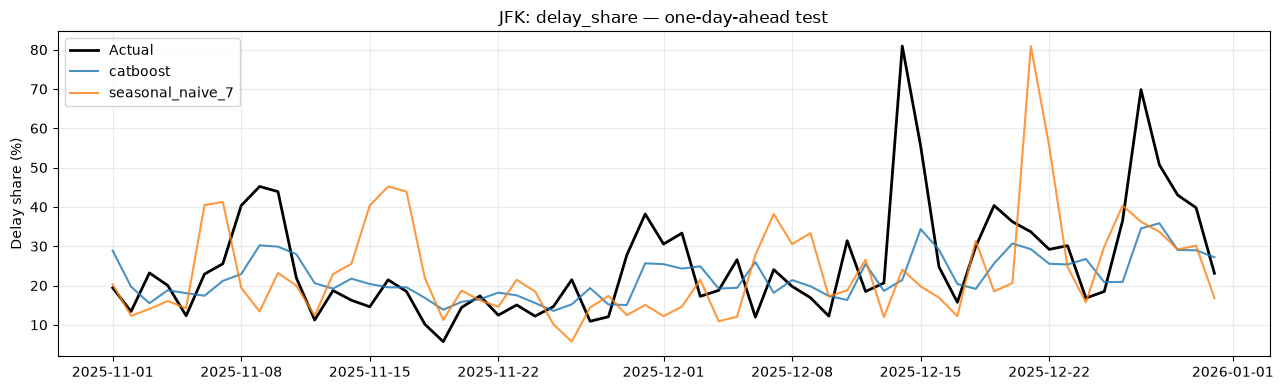

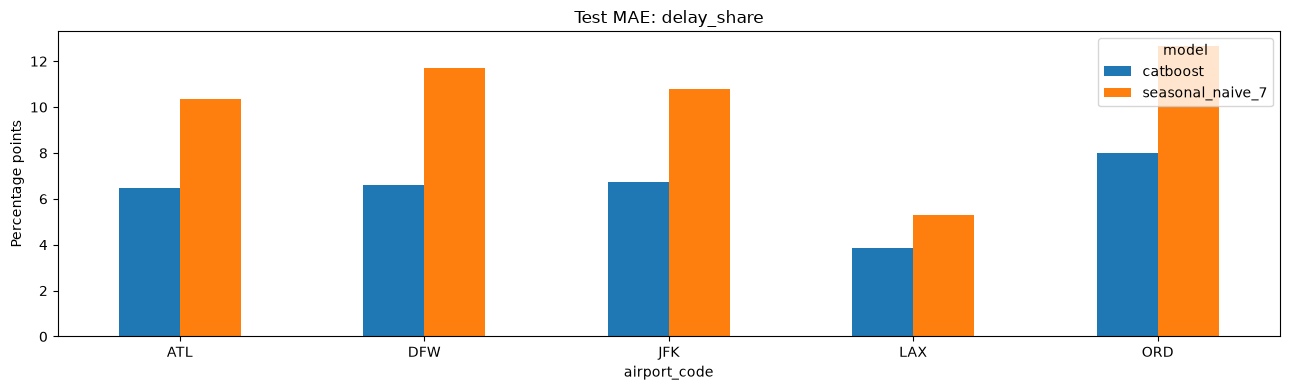

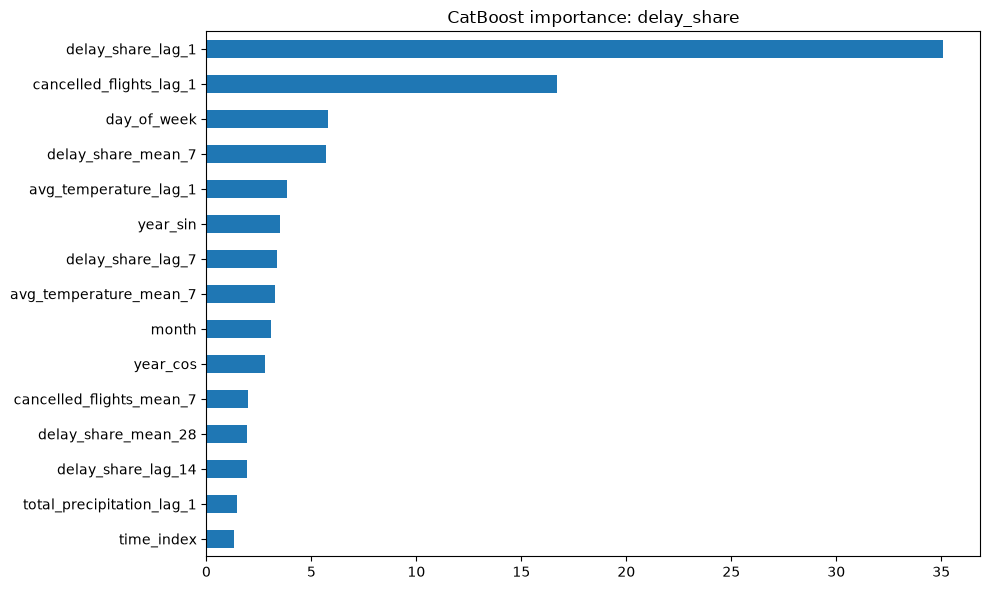

In [9]:
PLOT_AIRPORT = 'JFK'
PLOT_FROM = '2025-11-01'
PLOT_TO = '2025-12-31'
for target in TARGETS:
    part = test_predictions.loc[(test_predictions.airport_code == PLOT_AIRPORT) &
        (test_predictions.target == target) & test_predictions.flight_date.between(PLOT_FROM,PLOT_TO)]
    fig, ax = plt.subplots()
    actual = part.drop_duplicates('flight_date').sort_values('flight_date')
    ax.plot(actual.flight_date,actual.actual,label='Actual',color='black',linewidth=2)
    for name, group in part.groupby('model'):
        ax.plot(group.flight_date,group.prediction,label=name,alpha=.8)
    ax.set(title=f'{PLOT_AIRPORT}: {target} — one-day-ahead test',ylabel='Flights' if target=='total_flights' else 'Delay share (%)')
    ax.legend(); ax.grid(alpha=.25); fig.tight_layout()
    fig.savefig(OUT / f'forecast_{target}_{PLOT_AIRPORT}.png',dpi=160); plt.show()
    pivot = test_metrics.query("target == @target and airport_code != 'ALL'").pivot(index='airport_code',columns='model',values='MAE')
    ax = pivot.plot.bar(rot=0,title=f'Test MAE: {target}')
    ax.set_ylabel('Flights' if target=='total_flights' else 'Percentage points')
    ax.figure.tight_layout(); ax.figure.savefig(OUT / f'mae_{target}.png',dpi=160); plt.show()
    importance = pd.Series(final_models[target].feature_importances_,index=FEATURES).sort_values().tail(15)
    ax = importance.plot.barh(title=f'CatBoost importance: {target}',figsize=(10,6))
    ax.figure.tight_layout(); ax.figure.savefig(OUT / f'importance_{target}.png',dpi=160); plt.show()


## 9. Сохранение эксперимента и выводы
Сохраняем снимок входных данных, признаки, временные границы, параметры, метрики, тестовые прогнозы и версии пакетов. Выводы формируются из реальных расчётов. Не обещаем заранее, что сложная модель победит baseline.


In [10]:
validation_metrics.to_csv(OUT / 'validation_metrics.csv',index=False,encoding='utf-8-sig')
test_metrics.to_csv(OUT / 'test_metrics.csv',index=False,encoding='utf-8-sig')
comparison.to_csv(OUT / 'test_comparison.csv',index=False,encoding='utf-8-sig')
tuning_table.to_csv(OUT / 'tuning.csv',index=False)
pd.concat([validation_predictions,test_predictions]).to_csv(OUT / 'backtest_predictions.csv',index=False,encoding='utf-8-sig')
versions = {name:importlib.metadata.version(name) for name in ['pandas','numpy','SQLAlchemy','scikit-learn','catboost','matplotlib']}
manifest = {'run_id':RUN_ID,'scenario':'retrospective rolling one-day-ahead; observed history through t-1',
            'targets':TARGETS,'features':FEATURES,'seed':SEED,'train_end':str(TRAIN_END.date()),
            'validation_end':str(VALID_END.date()),'test_end':str(TEST_END.date()),
            'selected_catboost_parameters':selected,'base_parameters':BASE_PARAMS,
            'chosen_model_by_validation':chosen_model,'snapshot_sha256':snapshot_sha256,
            'python':platform.python_version(),'versions':versions}
(OUT / 'experiment.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
lines = []
for target in TARGETS:
    unit = 'рейсов' if target == 'total_flights' else 'процентного пункта'
    for name in ['seasonal_naive_7','catboost']:
        row = test_metrics.query("target == @target and model == @name and airport_code == 'ALL'").iloc[0]
        lines.append(f'{target}, {name}: MAE = {row.MAE:.3f} {unit}; RMSE = {row.RMSE:.3f}.')
    lines.append(f'Рабочая модель, выбранная по валидации: {chosen_model[target]}.')
report = '\n'.join(lines)
print(report)
(OUT / 'results_summary.txt').write_text(report,encoding='utf-8')
print('Результаты:', OUT)
print('Модели оценки:', MODEL_DIR)


total_flights, seasonal_naive_7: MAE = 27.242 рейсов; RMSE = 61.475.
total_flights, catboost: MAE = 27.088 рейсов; RMSE = 46.738.
Рабочая модель, выбранная по валидации: seasonal_naive_7.
delay_share, seasonal_naive_7: MAE = 10.162 процентного пункта; RMSE = 14.736.
delay_share, catboost: MAE = 6.332 процентного пункта; RMSE = 9.634.
Рабочая модель, выбранная по валидации: catboost.
Результаты: d:\MIREA\ПАС\aviation-analytics\reports\forecasting\20261026T151541584865Z
Модели оценки: d:\MIREA\ПАС\aviation-analytics\models\forecasting\20261026T151541584865Z


## 10. Демонстрационный прогноз на день после конца истории
Теперь CatBoost с уже выбранными настройками обучается на всей истории. Это отдельные модели для дальнейшего применения, а не модели тестовой оценки. Прогнозируем 1 января 2026 относительно истории до 31 декабря 2025. Это не прогноз на текущую календарную дату.

В будущую строку не подставляем известные ответы или фактическую погоду. Календарь вычисляется по дате; исторические признаки — по прошлым строкам. Для применения сохраняются обе модели, а `selected_for_use` указывает выбор по валидации.


In [11]:
next_date = raw.flight_date.max() + pd.Timedelta(days=1)
future = raw.groupby('airport_code',as_index=False).tail(1).copy()
future['flight_date'] = next_date
for col in num_cols:
    if col != 'airport_id':
        future[col] = np.nan
future_features = make_features(pd.concat([raw,future],ignore_index=True))
future_features = future_features.loc[future_features.flight_date == next_date].copy()
assert len(future_features) == len(AIRPORTS)
assert not future_features[required_history].isna().any().any()
future_parts = []
for target in TARGETS:
    production = CatBoostRegressor(**{**BASE_PARAMS,**selected[target]})
    production.fit(data[FEATURES],data[target],cat_features=['airport_code'],verbose=False)
    production.save_model(str(MODEL_DIR / f'{target}_full_history.cbm'))
    for name, values in [('seasonal_naive_7',future_features[f'{target}_lag_7']),('catboost',production.predict(future_features[FEATURES]))]:
        out = future_features[['airport_code','flight_date']].copy()
        out['history_through'] = raw.flight_date.max()
        out['target'] = target; out['model'] = name
        out['prediction'] = bounded(values,target)
        out['selected_for_use'] = name == chosen_model[target]
        future_parts.append(out)
future_predictions = pd.concat(future_parts,ignore_index=True)
future_predictions.to_csv(OUT / 'next_day_predictions.csv',index=False,encoding='utf-8-sig')
display(future_predictions.query('selected_for_use').round(3))
print('Тетрадь завершена. PostgreSQL не изменён.')


C:\Users\Админ\AppData\Local\Temp\ipykernel_9952\2678642232.py:25: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(future_predictions.query('selected_for_use').round(3))


,airport_code,flight_date,history_through,target,model,prediction,selected_for_use
0,ATL,2026-01-01,2025-12-31,total_flights,seasonal_naive_7,650.000,True
1,DFW,2026-01-01,2025-12-31,total_flights,seasonal_naive_7,728.000,True
2,JFK,2026-01-01,2025-12-31,total_flights,seasonal_naive_7,240.000,True
3,LAX,2026-01-01,2025-12-31,total_flights,seasonal_naive_7,451.000,True
4,ORD,2026-01-01,2025-12-31,total_flights,seasonal_naive_7,646.000,True
15,ATL,2026-01-01,2025-12-31,delay_share,catboost,23.652,True
16,DFW,2026-01-01,2025-12-31,delay_share,catboost,25.628,True
17,JFK,2026-01-01,2025-12-31,delay_share,catboost,24.513,True
18,LAX,2026-01-01,2025-12-31,delay_share,catboost,24.472,True
19,ORD,2026-01-01,2025-12-31,delay_share,catboost,32.408,True


Тетрадь завершена. PostgreSQL не изменён.
